In [1]:
#Imports

import os
import numpy as np
import pandas as pd
# from ucimlrepo import fetch_ucirepo  # Not needed: CSV already exists locally
import re
from urllib.parse import urlparse
import time
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.metrics import confusion_matrix, classification_report, roc_curve

In [2]:
LOCAL_CSV = "phiusiil_phishing.csv"

# 1. Fetch from UCI once or load locally if already saved
if not os.path.exists(LOCAL_CSV):
    print(f"'{LOCAL_CSV}' not found locally. Fetching from UCI repo (ID 967)...")
    phiusiil = fetch_ucirepo(id=967)
    X_raw = phiusiil.data.features
    y_raw = phiusiil.data.targets
    df_raw = pd.concat([X_raw, y_raw], axis=1)
    df_raw.to_csv(LOCAL_CSV, index=False)
    print(f"Saved dataset locally to '{LOCAL_CSV}'.")
else:
    print(f"Loading dataset from local file '{LOCAL_CSV}'...")

df = pd.read_csv(LOCAL_CSV)

# 2. Check shape and dimensions before cleaning
print("\n--- Raw Dataset Shape ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

# 3. Inspect label coding and class balance
label_col = "label"
print(f"\n--- Target Column: '{label_col}' ---")
print("Class counts (Raw):")
print(df[label_col].value_counts(dropna=False))
print("\nClass percentages (Raw):")
print(df[label_col].value_counts(normalize=True) * 100)

print("\n--- Sample URLs with Target Labels ---")
print(df[["URL", label_col]].head(10))

# 4. Check for missing values
missing = df.isnull().sum().sum()
print(f"\n--- Missing Values ---")
print(f"Total missing entries: {missing}")

# 5. Check exact duplicates and drop them before splitting
exact_duplicates = df.duplicated(subset=["URL"]).sum()
print(f"\n--- Duplicates ---")
print(f"Exact duplicate URLs found: {exact_duplicates}")

df = df.drop_duplicates(subset=["URL"]).reset_index(drop=True)
print(f"Rows after dropping duplicates: {df.shape[0]}")

# 6. Check for suspicious / pre-computed columns
suspicious_cols = ["TLDLegitimateProb", "URLSimilarityIndex", "FILENAME"]
found_suspicious = [c for c in suspicious_cols if c in df.columns]
print(f"\n--- Audit Columns Checked ---")
print(f"Columns found: {found_suspicious}")

Loading dataset from local file 'phiusiil_phishing.csv'...



--- Raw Dataset Shape ---
Rows: 235795, Columns: 55

--- Target Column: 'label' ---
Class counts (Raw):
label
1    134850
0    100945
Name: count, dtype: int64

Class percentages (Raw):
label
1    57.189508
0    42.810492
Name: proportion, dtype: float64

--- Sample URLs with Target Labels ---
                                  URL  label
0    https://www.southbankmosaics.com      1
1            https://www.uni-mainz.de      1
2      https://www.voicefmradio.co.uk      1
3         https://www.sfnmjournal.com      1
4  https://www.rewildingargentina.org      1
5     https://www.globalreporting.org      1
6          https://www.saffronart.com      1
7          https://www.nerdscandy.com      1
8      https://www.hyderabadonline.in      1
9                 https://www.aap.org      1

--- Missing Values ---
Total missing entries: 0

--- Duplicates ---
Exact duplicate URLs found: 425
Rows after dropping duplicates: 235370

--- Audit Columns Checked ---
Columns found: ['TLDLegitimateProb', '

In [3]:
# List of typical sensitive/suspicious tokens found in phishing URLs
SUSPICIOUS_TOKENS = ['login', 'verify', 'secure', 'account', 'update', 'signin', 'banking', 'confirm']
IP_REGEX = re.compile(r'^(?:\d{1,3}\.){3}\d{1,3}$')

def extract_single_url_features(url_str):
    url_str = str(url_str).strip()

    # Prepend scheme if missing so urlparse extracts netloc/hostname properly
    if not (url_str.startswith('http://') or url_str.startswith('https://')):
        parsed = urlparse('http://' + url_str)
        uses_https = 0
    else:
        parsed = urlparse(url_str)
        uses_https = 1 if parsed.scheme.lower() == 'https' else 0

    hostname = parsed.hostname or ''
    path = parsed.path or ''

    # 1. URL length
    url_length = len(url_str)

    # 2. Hostname length
    hostname_length = len(hostname)

    # 3. Dot count
    dot_count = url_str.count('.')

    # 4. Hyphen count in hostname
    hyphen_count = hostname.count('-')

    # 5. Digits count & ratio
    digit_count = sum(c.isdigit() for c in url_str)
    digit_ratio = digit_count / url_length if url_length > 0 else 0.0

    # 6. Special symbols (@, ?, =, &, %)
    special_symbols = sum(url_str.count(sym) for sym in ['@', '?', '=', '&', '%'])

    # 7. Subdomain count
    host_parts = hostname.split('.')
    subdomain_count = max(0, len(host_parts) - 2) if len(host_parts) > 2 else 0

    # 8. Host is IP address
    host_is_ip = 1 if IP_REGEX.match(hostname) else 0

    # 9. Suspicious keywords count
    url_lower = url_str.lower()
    suspicious_words = sum(1 for kw in SUSPICIOUS_TOKENS if kw in url_lower)

    # 10. Path length ratio
    path_len_ratio = len(path) / url_length if url_length > 0 else 0.0

    # 11. TLD length
    tld = host_parts[-1] if len(host_parts) >= 2 else ''
    tld_length = len(tld)

    return [
        url_length,
        hostname_length,
        dot_count,
        hyphen_count,
        digit_count,
        digit_ratio,
        special_symbols,
        subdomain_count,
        uses_https,
        host_is_ip,
        suspicious_words,
        path_len_ratio,
        tld_length
    ]

feature_columns = [
    'url_length',
    'hostname_length',
    'dot_count',
    'hyphen_count',
    'digit_count',
    'digit_ratio',
    'special_symbols',
    'subdomain_count',
    'uses_https',
    'host_is_ip',
    'suspicious_words',
    'path_len_ratio',
    'tld_length'
]

print("Feature extraction function and column definitions ready.")

Feature extraction function and column definitions ready.


In [4]:
print(f"Extracting 12 URL-only features for {len(df)} URLs...")
start_time = time.time()

# Extract list of rows for fast execution (~10-20 seconds for 235k rows)
features_data = [extract_single_url_features(u) for u in df['URL']]
X_zero_packet = pd.DataFrame(features_data, columns=feature_columns)

elapsed = time.time() - start_time
print(f"Extraction complete in {elapsed:.2f} seconds.")
print(f"Feature matrix shape: {X_zero_packet.shape}")

Extracting 12 URL-only features for 235370 URLs...


Extraction complete in 1.76 seconds.
Feature matrix shape: (235370, 13)


In [5]:
# Check for nulls/infinities
print("Missing values in extracted features:")
print(X_zero_packet.isnull().sum())

# Display descriptive statistics
print("\n--- Extracted Feature Summary ---")
print(X_zero_packet.describe().T[['mean', 'std', 'min', 'max']])

# Save to parquet/csv so you don't have to recompute next time
X_zero_packet['label'] = df['label'].values
X_zero_packet.to_csv('phiusiil_zero_packet_features.csv', index=False)
print("\nSaved extracted features and labels to 'phiusiil_zero_packet_features.csv'.")

Missing values in extracted features:
url_length          0
hostname_length     0
dot_count           0
hyphen_count        0
digit_count         0
digit_ratio         0
special_symbols     0
subdomain_count     0
uses_https          0
host_is_ip          0
suspicious_words    0
path_len_ratio      0
tld_length          0
dtype: int64

--- Extracted Feature Summary ---
                       mean        std   min          max
url_length        35.339920  41.233000  14.0  6097.000000
hostname_length   21.454523   9.126058   4.0   110.000000
dot_count          2.256995   0.922701   1.0    99.000000
hyphen_count       0.280996   0.750935   0.0    26.000000
digit_count        1.880898  11.898945   0.0  2011.000000
digit_ratio        0.028286   0.070184   0.0     0.684211
special_symbols    0.161444   1.986044   0.0   312.000000
subdomain_count    1.164894   0.600646   0.0    10.000000
uses_https         0.780622   0.413826   0.0     1.000000
host_is_ip         0.002575   0.050676   0.0    


Saved extracted features and labels to 'phiusiil_zero_packet_features.csv'.


In [6]:
# Load the cleaned dataset if not already in memory
# df = pd.read_csv("phiusiil_phishing.csv").drop_duplicates(subset=["URL"]).reset_index(drop=True)

# Define the classification dictionary for all 55 columns in PhiUSIIL
column_audit = {
    # 1. Identifiers and Target
    'FILENAME': ('Identifier / Dropped', 'Row identifier / file name; dropped before modelling.'),
    'URL': ('Raw Input (URL-only source)', 'Raw URL string used to compute our 12 zero-packet features.'),
    'Domain': ('URL-only (Raw string)', 'Domain string; represented via our custom hostname/TLD features.'),
    'TLD': ('URL-only (Raw string)', 'Top-Level Domain string; represented via tld_length.'),
    'Title': ('Needs Web Page (Excluded)', 'Requires downloading HTML <title> tag.'),
    'label': ('Target Label', '1 = Legitimate, 0 = Phishing (flip to 1 = Phishing for evaluation).'),

    # 2. Suspicious / Pre-computed Scores (Investigated in Experiment A)
    'URLSimilarityIndex': ('Unclear / Pre-computed', 'Pre-computed similarity score; investigated in Experiment A.'),
    'CharContinuationRate': ('URL-only (Excluded pre-computed)', 'Dataset pre-computed character sequence metric.'),
    'TLDLegitimateProb': ('Unclear / Needs External Data', 'Pre-computed TLD probability; investigated in Experiment A.'),
    'URLCharProb': ('Unclear / Needs External Data', 'Pre-computed character probability distribution.'),

    # 3. Dataset's Pre-computed Lexical Columns (Excluded in favor of our own extraction)
    'URLLength': ('URL-only (Recomputed)', 'Replaced by our own url_length.'),
    'DomainLength': ('URL-only (Recomputed)', 'Replaced by our own hostname_length.'),
    'IsDomainIP': ('URL-only (Recomputed)', 'Replaced by our own host_is_ip.'),
    'TLDLength': ('URL-only (Recomputed)', 'Replaced by our own tld_length.'),
    'NoOfSubDomain': ('URL-only (Recomputed)', 'Replaced by our own subdomain_count.'),
    'HasObfuscation': ('URL-only (Dataset pre-computed)', 'Replaced by our own special_symbols check.'),
    'NoOfObfuscatedChar': ('URL-only (Dataset pre-computed)', 'Replaced by our own special_symbols check.'),
    'ObfuscationRatio': ('URL-only (Dataset pre-computed)', 'Replaced by our own special_symbols check.'),
    'NoOfLettersInURL': ('URL-only (Dataset pre-computed)', 'Omitted to keep the 12-feature set compact.'),
    'LetterRatioInURL': ('URL-only (Dataset pre-computed)', 'Omitted to keep the 12-feature set compact.'),
    'NoOfDegitsInURL': ('URL-only (Recomputed)', 'Replaced by our own digit_count.'),
    'DegitRatioInURL': ('URL-only (Recomputed)', 'Replaced by our own digit_ratio.'),
    'NoOfEqualsInURL': ('URL-only (Recomputed)', 'Grouped into our own special_symbols.'),
    'NoOfQMarkInURL': ('URL-only (Recomputed)', 'Grouped into our own special_symbols.'),
    'NoOfAmpersandInURL': ('URL-only (Recomputed)', 'Grouped into our own special_symbols.'),
    'NoOfOtherSpecialCharsInURL': ('URL-only (Recomputed)', 'Grouped into our own special_symbols / dot_count / hyphen_count.'),
    'SpacialCharRatioInURL': ('URL-only (Dataset pre-computed)', 'Replaced by our own special_symbols.'),
    'IsHTTPS': ('URL-only (Recomputed)', 'Replaced by our own uses_https.'),
    'Bank': ('URL-only (Recomputed)', 'Grouped into our own suspicious_words.'),
    'Pay': ('URL-only (Recomputed)', 'Grouped into our own suspicious_words.'),
    'Crypto': ('URL-only (Recomputed)', 'Grouped into our own suspicious_words.'),

    # 4. Web Page / HTML / DOM Features (Strictly Excluded by Zero-Packet Rule)
    'LineOfCode': ('Needs Web Page (Excluded)', 'Requires downloading page source code.'),
    'LargestLineLength': ('Needs Web Page (Excluded)', 'Requires downloading page source code.'),
    'HasTitle': ('Needs Web Page (Excluded)', 'Requires parsing HTML DOM.'),
    'DomainTitleMatchScore': ('Needs Web Page (Excluded)', 'Requires comparing URL against HTML <title>.'),
    'URLTitleMatchScore': ('Needs Web Page (Excluded)', 'Requires comparing URL against HTML <title>.'),
    'HasFavicon': ('Needs Web Page (Excluded)', 'Requires checking HTML <link> tags / fetching favicon.'),
    'Robots': ('Needs Web Page (Excluded)', 'Requires network request for robots.txt.'),
    'IsResponsive': ('Needs Web Page (Excluded)', 'Requires rendering CSS/HTML viewport tags.'),
    'NoOfURLRedirect': ('Needs Web Page (Excluded)', 'Requires following HTTP network redirects.'),
    'NoOfSelfRedirect': ('Needs Web Page (Excluded)', 'Requires following HTTP network redirects.'),
    'HasDescription': ('Needs Web Page (Excluded)', 'Requires parsing HTML <meta> description.'),
    'NoOfPopup': ('Needs Web Page (Excluded)', 'Requires inspecting HTML/JS scripts.'),
    'NoOfiFrame': ('Needs Web Page (Excluded)', 'Requires parsing HTML <iframe> tags.'),
    'HasExternalFormSubmit': ('Needs Web Page (Excluded)', 'Requires parsing HTML <form> actions.'),
    'HasSocialNet': ('Needs Web Page (Excluded)', 'Requires inspecting page links/scripts.'),
    'HasSubmitButton': ('Needs Web Page (Excluded)', 'Requires parsing HTML <input>/<button> tags.'),
    'HasHiddenFields': ('Needs Web Page (Excluded)', 'Requires parsing HTML hidden input fields.'),
    'HasPasswordField': ('Needs Web Page (Excluded)', 'Requires parsing HTML password input fields.'),
    'HasCopyrightInfo': ('Needs Web Page (Excluded)', 'Requires parsing page text/footer.'),
    'NoOfImage': ('Needs Web Page (Excluded)', 'Requires parsing HTML <img> tags.'),
    'NoOfCSS': ('Needs Web Page (Excluded)', 'Requires parsing HTML stylesheet links.'),
    'NoOfJS': ('Needs Web Page (Excluded)', 'Requires parsing HTML <script> tags.'),
    'NoOfSelfRef': ('Needs Web Page (Excluded)', 'Requires parsing HTML <a> anchor tags.'),
    'NoOfEmptyRef': ('Needs Web Page (Excluded)', 'Requires parsing HTML <a> anchor tags.'),
    'NoOfExternalRef': ('Needs Web Page (Excluded)', 'Requires parsing HTML <a> anchor tags.')
}

# Build audit table matching the exact columns present in your dataframe
audit_rows = []
for col in df.columns:
    cat, reason = column_audit.get(col, ('Unclear', 'Unmapped column - check manually'))
    audit_rows.append({'Column Name': col, 'Category': cat, 'Treatment & Justification': reason})

audit_df = pd.DataFrame(audit_rows)

print("--- Summary of Dataset Column Classifications ---")
print(audit_df['Category'].value_counts())

# Save the audit table for the report
audit_df.to_csv('dataset_column_audit.csv', index=False)
print("\nSaved full 55-column classification table to 'dataset_column_audit.csv'.")

--- Summary of Dataset Column Classifications ---
Category
Needs Web Page (Excluded)           26
URL-only (Recomputed)               15
URL-only (Dataset pre-computed)      6
URL-only (Raw string)                2
Unclear / Needs External Data        2
Raw Input (URL-only source)          1
Unclear / Pre-computed               1
URL-only (Excluded pre-computed)     1
Target Label                         1
Name: count, dtype: int64

Saved full 55-column classification table to 'dataset_column_audit.csv'.


In [7]:
# Flip label so 1 = Phishing (positive class) and 0 = Legitimate (negative class)
X_zero_packet['is_phishing'] = (df['label'] == 0).astype(int)

# Also keep the two suspicious columns in a separate audit dataframe for tomorrow's Experiment A
audit_features_df = X_zero_packet.copy()
audit_features_df['TLDLegitimateProb'] = df['TLDLegitimateProb'].values
audit_features_df['URLSimilarityIndex'] = df['URLSimilarityIndex'].values

audit_features_df.to_csv('phiusiil_working_dataset.csv', index=False)
print("Saved working dataset with 'is_phishing' (1=Phishing, 0=Legitimate) and audit columns!")
print(audit_features_df['is_phishing'].value_counts())

Saved working dataset with 'is_phishing' (1=Phishing, 0=Legitimate) and audit columns!
is_phishing
0    134850
1    100520
Name: count, dtype: int64


In [8]:
# 1. Load the working dataset
df = pd.read_csv('phiusiil_working_dataset.csv')

# 2. Define feature groups
zero_packet_features = [
    'url_length', 'hostname_length', 'dot_count', 'hyphen_count',
    'digit_count', 'digit_ratio', 'special_symbols', 'subdomain_count',
    'uses_https', 'host_is_ip', 'suspicious_words', 'path_len_ratio', 'tld_length'
]
suspicious_features = ['TLDLegitimateProb', 'URLSimilarityIndex']
target = 'is_phishing'

X = df[zero_packet_features + suspicious_features]
y = df[target]

# 3. Stratified Split (60% Train, 20% Validation, 20% Test)
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)

print("--- Data Split Sizes ---")
print(f"Train:      {X_train.shape[0]} rows (60%)")
print(f"Validation: {X_val.shape[0]} rows (20%)")
print(f"Test:       {X_test.shape[0]} rows (20%)")

# 4. Experiment A: Single Feature ROC-AUC (Evaluated Out-of-Sample on Validation Data)
print("\n--- Experiment A: Single Feature ROC-AUC (Validation Set) ---")
for col in suspicious_features:
    # Check direction on train, evaluate out-of-sample on validation
    train_auc = roc_auc_score(y_train, X_train[col])
    val_scores = X_val[col] if train_auc >= 0.5 else -X_val[col]
    val_auc = roc_auc_score(y_val, val_scores)
    print(f"{col} alone (Validation AUC): {val_auc:.4f}")

# 5. Experiment A: Model Comparison With vs. Without Suspicious Columns (Evaluated on Validation Set)
# Fit scalers strictly on training data, transform validation data
scaler_without = StandardScaler().fit(X_train[zero_packet_features])
scaler_with = StandardScaler().fit(X_train[zero_packet_features + suspicious_features])

X_train_lr_without = scaler_without.transform(X_train[zero_packet_features])
X_val_lr_without   = scaler_without.transform(X_val[zero_packet_features])

X_train_lr_with = scaler_with.transform(X_train[zero_packet_features + suspicious_features])
X_val_lr_with   = scaler_with.transform(X_val[zero_packet_features + suspicious_features])

models_exp_a = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

print("\n--- Experiment A: Out-of-Sample ROC-AUC Jump (Validation Set) ---")
exp_a_val_summary = {}
for name, model in models_exp_a.items():
    # Train on X_train, Evaluate WITHOUT suspicious features on X_val
    if name == "Logistic Regression":
        model.fit(X_train_lr_without, y_train)
        preds_without = model.predict_proba(X_val_lr_without)[:, 1]
    else:
        model.fit(X_train[zero_packet_features], y_train)
        preds_without = model.predict_proba(X_val[zero_packet_features])[:, 1]

    auc_without = roc_auc_score(y_val, preds_without)

    # Train on X_train, Evaluate WITH suspicious features on X_val
    if name == "Logistic Regression":
        model.fit(X_train_lr_with, y_train)
        preds_with = model.predict_proba(X_val_lr_with)[:, 1]
    else:
        model.fit(X_train[zero_packet_features + suspicious_features], y_train)
        preds_with = model.predict_proba(X_val[zero_packet_features + suspicious_features])[:, 1]

    auc_with = roc_auc_score(y_val, preds_with)
    exp_a_val_summary[name] = {
        "without": round(float(auc_without), 4),
        "with": round(float(auc_with), 4),
        "jump": round(float(auc_with - auc_without), 4)
    }

    print(f"{name} (Validation Set):")
    print(f"  Without oracle columns: {auc_without:.4f}")
    print(f"  With oracle columns:    {auc_with:.4f}")
    print(f"  Out-of-Sample Jump:     +{auc_with - auc_without:.4f}")

--- Data Split Sizes ---
Train:      141222 rows (60%)
Validation: 47074 rows (20%)
Test:       47074 rows (20%)

--- Experiment A: Single Feature ROC-AUC (Validation Set) ---
TLDLegitimateProb alone (Validation AUC): 0.6076
URLSimilarityIndex alone (Validation AUC): 0.9959

--- Experiment A: Out-of-Sample ROC-AUC Jump (Validation Set) ---


Logistic Regression (Validation Set):
  Without oracle columns: 0.9956
  With oracle columns:    0.9999
  Out-of-Sample Jump:     +0.0042


Decision Tree (Validation Set):
  Without oracle columns: 0.9956
  With oracle columns:    0.9999
  Out-of-Sample Jump:     +0.0044


Training models and calculating metrics on the Test Set...



--- Experiment B: Test Set Results (Threshold = 0.5) ---
                     ROC-AUC  Precision  Recall  F1-Score
Model                                                    
Logistic Regression   0.9961     0.9991  0.9864    0.9927
Decision Tree         0.9948     0.9976  0.9908    0.9942
Random Forest         0.9969     0.9978  0.9914    0.9946


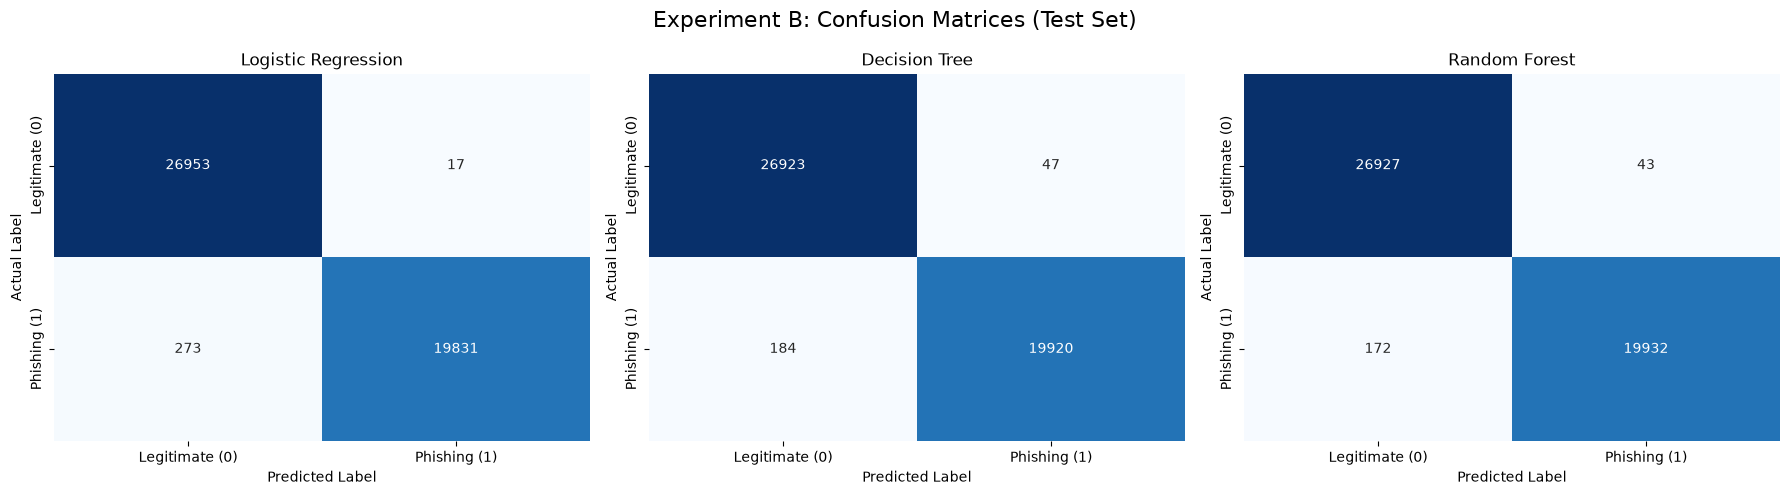

In [9]:
# Ensure variables from Day 3 are available (X_train, X_test, y_train, y_test, zero_packet_features)
# If you restarted your notebook, re-run the Day 3 split cell first!

# 1. Scale data for Logistic Regression strictly on the training set
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train[zero_packet_features])
X_test_scaled = scaler.transform(X_test[zero_packet_features])

# Decision Trees and Random Forests do not require scaling
X_train_tree = X_train[zero_packet_features]
X_test_tree = X_test[zero_packet_features]

# 2. Initialize Models (default settings as requested)
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

# 3. Train and Evaluate
results = []
cms = {}

print("Training models and calculating metrics on the Test Set...\n")

for name, model in models.items():
    # Select appropriate training/test sets
    X_tr = X_train_scaled if name == "Logistic Regression" else X_train_tree
    X_te = X_test_scaled if name == "Logistic Regression" else X_test_tree

    # Train
    model.fit(X_tr, y_train)

    # Predict (Threshold = 0.5)
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]

    # Metrics
    auc = roc_auc_score(y_test, y_prob)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({
        "Model": name,
        "ROC-AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    # Confusion Matrix
    cms[name] = confusion_matrix(y_test, y_pred)

# 4. Display Metrics Table
results_df = pd.DataFrame(results).set_index("Model")
print("--- Experiment B: Test Set Results (Threshold = 0.5) ---")
print(results_df.round(4))

# 5. Plot Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Experiment B: Confusion Matrices (Test Set)', fontsize=16)

for ax, (name, cm) in zip(axes, cms.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Legitimate (0)', 'Phishing (1)'],
                yticklabels=['Legitimate (0)', 'Phishing (1)'])
    ax.set_title(name)
    ax.set_ylabel('Actual Label')
    ax.set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()

In [10]:
# Ensure Random Forest is trained or use the rf model from Day 4
# rf_model = models["Random Forest"] (assuming it's still in memory)

# 1. Get predicted probabilities on Validation and Test sets for Random Forest
# (Using Random Forest as it was the top-performing model in Experiment B)
val_probs = models["Random Forest"].predict_proba(X_val[zero_packet_features])[:, 1]
test_probs = models["Random Forest"].predict_proba(X_test_tree)[:, 1]

# 2. Find a threshold on the Validation set that guarantees FPR <= 1% (0.01)
fpr, tpr, thresholds = roc_curve(y_val, val_probs)

# Find thresholds where FPR <= 0.01
valid_indices = np.where(fpr <= 0.01)[0]
# Choose the threshold that maximizes TPR among those with FPR <= 0.01
best_idx = valid_indices[np.argmax(tpr[valid_indices])]
tuned_threshold = thresholds[best_idx]

print(f"--- Threshold Tuning ---")
print(f"Selected Validation Threshold for FPR <= 1%: {tuned_threshold:.4f}")
print(f"Corresponding Validation FPR: {fpr[best_idx]:.4f}")
print(f"Corresponding Validation TPR (Recall): {tpr[best_idx]:.4f}")

# 3. Evaluate Tuned Threshold on the Test Set
test_preds_tuned = (test_probs >= tuned_threshold).astype(int)
cm_tuned = confusion_matrix(y_test, test_preds_tuned)

tn, fp, fn, tp = cm_tuned.ravel()
test_fpr = fp / (fp + tn)
test_tpr = tp / (tp + fn)

print(f"\n--- Test Set Performance at Tuned Threshold ({tuned_threshold:.4f}) ---")
print(f"Test False Positive Rate (FPR): {test_fpr:.4f} ({fp} false positives out of {fp+tn} legitimate URLs)")
print(f"Test True Positive Rate (Recall): {test_tpr:.4f} ({tp} phishing caught out of {tp+fn} total phishing)")
print("\nConfusion Matrix (Tuned):")
print(cm_tuned)

# 4. Error Analysis: Inspect False Positives and False Negatives from Test Set
# Load original clean dataframe to fetch the raw URL strings
original_df = pd.read_csv('phiusiil_phishing.csv').drop_duplicates(subset=['URL']).reset_index(drop=True)
test_urls = original_df.loc[X_test.index, 'URL'].reset_index(drop=True)

test_df_eval = pd.DataFrame({
    'URL': test_urls,
    'Actual': y_test.values,
    'Predicted_Prob': test_probs,
    'Predicted_Label': test_preds_tuned
})

# Filter False Positives (Actual = 0, Predicted = 1)
false_positives = test_df_eval[(test_df_eval['Actual'] == 0) & (test_df_eval['Predicted_Label'] == 1)]
# Filter False Negatives (Actual = 1, Predicted = 0)
false_negatives = test_df_eval[(test_df_eval['Actual'] == 1) & (test_df_eval['Predicted_Label'] == 0)]

print(f"\n--- Error Analysis Sample ---")
print(f"Total False Positives on Test Set: {len(false_positives)}")
print(f"Total False Negatives on Test Set: {len(false_negatives)}")

print("\nSample False Positives (Legitimate URLs wrongly flagged as Phishing):")
print(false_positives[['URL', 'Predicted_Prob']].head(5))

print("\nSample False Negatives (Phishing URLs missed by the model):")
print(false_negatives[['URL', 'Predicted_Prob']].head(5))

--- Threshold Tuning ---
Selected Validation Threshold for FPR <= 1%: 0.0809
Corresponding Validation FPR: 0.0095
Corresponding Validation TPR (Recall): 0.9934

--- Test Set Performance at Tuned Threshold (0.0809) ---
Test False Positive Rate (FPR): 0.0092 (248 false positives out of 26970 legitimate URLs)
Test True Positive Rate (Recall): 0.9933 (19970 phishing caught out of 20104 total phishing)

Confusion Matrix (Tuned):
[[26722   248]
 [  134 19970]]



--- Error Analysis Sample ---
Total False Positives on Test Set: 248
Total False Negatives on Test Set: 134

Sample False Positives (Legitimate URLs wrongly flagged as Phishing):
                                           URL  Predicted_Prob
197                        https://www.pc.game        0.189161
224     https://www.hannelore-kohl-stiftung.de        0.288152
478   https://www.nationalcouncilofchurches.us        0.110775
675                 https://www.577records.com        0.142487
1140    https://www.reiner-lemoine-stiftung.de        0.288152

Sample False Negatives (Phishing URLs missed by the model):
                                       URL  Predicted_Prob
702           https://what.promerc.repl.co        0.001669
748                     https://www.cfg.me        0.000000
768                https://s.smcbacmzu.icu        0.002332
1037    https://www.michelonturismo.com.br        0.010300
1277  https://dev-poliflek.pantheonsite.io        0.000000


In [11]:
import json

# Export real empirical Random Forest test set confusion matrices across thresholds for the website slider
total_legit_test = int((y_test == 0).sum())
total_phish_test = int((y_test == 1).sum())

sample_thresholds = sorted(list(set(
    np.round(np.linspace(0.01, 0.99, 99), 4).tolist() + [round(float(tuned_threshold), 4), 0.5000]
)))

slider_curve = []
for tau in sample_thresholds:
    preds = (test_probs >= tau).astype(int)
    tn_c, fp_c, fn_c, tp_c = confusion_matrix(y_test, preds).ravel()
    fpr_c = fp_c / total_legit_test
    tpr_c = tp_c / total_phish_test
    prec_c = tp_c / (tp_c + fp_c) if (tp_c + fp_c) > 0 else 1.0
    f1_c = (2 * prec_c * tpr_c) / (prec_c + tpr_c) if (prec_c + tpr_c) > 0 else 0.0

    slider_curve.append({
        "threshold": round(float(tau), 4),
        "tn": int(tn_c),
        "fp": int(fp_c),
        "fn": int(fn_c),
        "tp": int(tp_c),
        "fpr": round(float(fpr_c), 4),
        "tpr": round(float(tpr_c), 4),
        "precision": round(float(prec_c), 4),
        "f1": round(float(f1_c), 4)
    })

with open("simulator_data.json", "w") as f:
    json.dump({
        "experiment_a_validation": exp_a_val_summary,
        "slider_curve": slider_curve
    }, f, indent=2)

print(f"Exported {len(slider_curve)} real test-set threshold points to 'simulator_data.json'!")

Exported 100 real test-set threshold points to 'simulator_data.json'!
